# 03 · Validating the model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mohammedelsayed741996-blip/berlin-data-portfolio/blob/main/consulting-financial-services/credit-downgrade-early-warning/notebooks/03_model_validation.ipynb)

An AUC on a test set says little about how a language model will behave on Monday morning. This notebook tests the text model the way you would test any model that reads language for a bank, a GenAI chatbot included: fixed inputs with a known right answer, checks across languages and sectors, calibration, and an honest list of what does not work.

In [1]:
import os, sys, subprocess, warnings
from pathlib import Path

REPO = "https://github.com/mohammedelsayed741996-blip/berlin-data-portfolio.git"
PROJECT = "consulting-financial-services/credit-downgrade-early-warning"

if "google.colab" in sys.modules:
    if not Path("/content/berlin-data-portfolio").exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO, "/content/berlin-data-portfolio"], check=True)
    os.chdir(f"/content/berlin-data-portfolio/{PROJECT}")
else:
    here = Path.cwd()
    while not (here / "src" / "downgrade_ews").exists() and here != here.parent:
        here = here.parent
    os.chdir(here)

sys.path.insert(0, str(Path.cwd() / "src"))
warnings.filterwarnings("ignore")
import pandas as pd
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 110)
from IPython.display import Image, display
print("Project folder:", Path.cwd().name)

Project folder: credit-downgrade-early-warning


In [2]:
from downgrade_ews import config as C, pipeline, features, models, explain, validation, reporting

tables = pipeline.load_tables()      # reads data/, or generates it if missing
run = pipeline.run(tables)           # text model, panel, four issuer models (about a minute)
print(f"{len(tables['news']):,} articles on {C.N_ISSUERS} issuers, {C.START} to {C.END}")

65,908 articles on 360 issuers, 2022-01 to 2026-09


## A shortcut found and removed

The first version of the article model did not mask sectors, cities or quarters. Its strongest words were "transport", "utilities" and "automotive". Sector shocks and reporting seasons happen to line up with downgrades in the training years, so the model learned the calendar instead of the language. That will not hold next year. Masking those tokens cost a little in-sample fit and removed the shortcut. The current top words are about cash, refinancing and outlooks.

In [3]:
explain.top_terms(run.text_model, 8, "en")[["term", "weight", "direction"]].reset_index(drop=True)

,term,weight,direction
0,cash,0.431809,raises risk
1,to negative,0.329427,raises risk
2,negativ,0.261009,raises risk
3,ratingagentur senkt,0.213678,raises risk
4,selbst wurde,0.213678,raises risk
5,senkt ausblick,0.213678,raises risk
6,rating selbst,0.213678,raises risk
7,selbst,0.213678,raises risk
8,positive,-0.305166,lowers risk
9,to positive,-0.305166,lowers risk


## Behavioural tests

In [4]:
validation.behavioural_tests(run.text_model, tables["issuers"])

,test,passed,detail
0,Invariance: 20 company names,20/20,score range 0.00e+00
1,Negation: denial scores lower than the problem,4/5,0.71->0.71; 0.68->0.67; 0.72->0.69; 0.63->0.68; 0.69->0.67
2,Directional: red flag raises score,2/3,0.50->0.57; 0.50->0.61; 0.59->0.55
3,Unseen paraphrases classified correctly,7/12,AUC 0.64


The company name has no effect, as intended. The other three results are mixed, and the reasons matter more than the score.

Start with denials. A sentence that denies liquidity problems scores almost as high as one that admits them. In this data that is right: the topic table below shows that issuers denying problems were downgraded within three months about 11% of the time, three to four times the rate after neutral news. Whether that holds for real companies should be checked before anyone relies on it.

Then unseen wording. On twelve sentences written by hand, in phrasings the templates never use, the model gets 7 right. A bag-of-words model trained on a limited vocabulary does not generalise far. With real news this is the main risk, and the fix would be human-labelled articles and a multilingual transformer or LLM classifier, tested with the same sentences.

In [5]:
validation.unseen_detail(run.text_model)

,sentence,label,score
0,[co] said cash would only last until the spring unless lenders agree to new terms.,1,0.698
1,Suppliers of [co] are demanding payment in advance.,1,0.586
2,[co] hired restructuring advisers to talk to bondholders.,1,0.599
3,Earnings at [co] collapsed and the company burned through cash.,1,0.701
4,[co] ist mit der Tilgung eines Kredits in Verzug.,1,0.596
5,Lieferanten von [co] verlangen Vorkasse.,1,0.568
6,[co] opened a new research centre and is hiring engineers.,0,0.574
7,[co] paid back a loan early from strong cash flow.,0,0.689
8,Orders at [co] reached a record high.,0,0.613
9,[co] eröffnet ein neues Werk und stellt Personal ein.,0,0.512


## Does the score follow the real topic?

The true topic of each article is known here, though the model never saw it. Scores by topic should rank credit stress first and good news last.

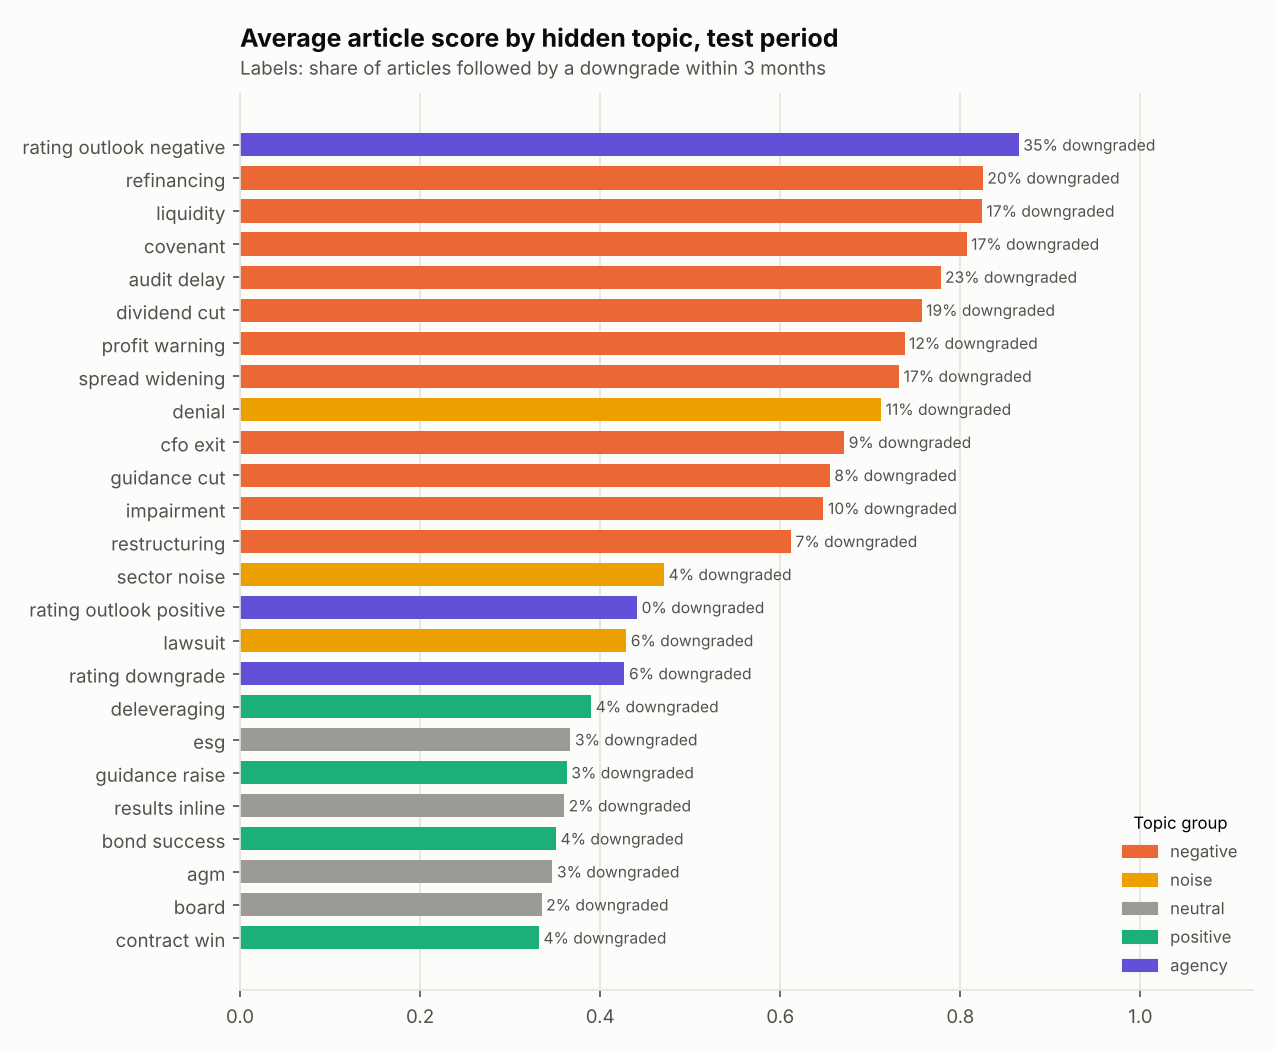

In [6]:
ts = validation.topic_scores(run.scored, C.TEST_START)
display(Image(filename=str(reporting.plot_topic_scores(ts, Path("outputs/figures/topic_scores.png")))))

## Languages, sectors and calibration

In [7]:
display(validation.by_language(run.scored, C.TEST_START))
display(validation.by_segment(run.test, run.results[models.FULL].scores, "sector"))

,language,articles,positive_share,roc_auc,pr_auc
0,de,5763,0.043,0.692,0.103
1,en,11673,0.059,0.680,0.132


,sector,rows,downgrade_rate,roc_auc,pr_auc
0,Automotive,372,0.043,0.686,0.273
1,Chemicals,453,0.055,0.759,0.262
2,Consumer goods,276,0.000,NaN,NaN
3,Healthcare,444,0.025,0.745,0.255
4,Industrials,516,0.029,0.778,0.121
5,Real estate,528,0.053,0.849,0.341
6,Retail,528,0.062,0.781,0.450
7,Telecoms,370,0.038,0.890,0.390
8,Transport & logistics,372,0.040,0.649,0.192
9,Utilities,451,0.022,0.790,0.226


German articles score about as well as English ones. Consumer goods had no downgrades in the test year, so it cannot be evaluated. The highest score bucket holds most of the downgrades; below it, scores are too low in absolute terms, so they should be read as a ranking until calibrated on recent data.

In [8]:
validation.calibration(run.test, run.results[models.FULL].scores)

,mean_score,observed,rows
bucket,,,
0,0.0018,0.0093,431
1,0.0032,0.0046,431
2,0.0045,0.0186,431
3,0.0061,0.0232,431
4,0.0080,0.0116,431
5,0.0105,0.0255,431
6,0.0139,0.0325,431
7,0.0199,0.0278,431
8,0.0346,0.0510,431


## Model card

The pipeline writes a one-page summary for model risk and for the client: purpose, data, design, results, validation and limits.

In [9]:
out = pipeline.write_outputs(run)
print(Path("outputs/model_card.md").read_text()[:1500])

# Model card: credit downgrade early warning

## Purpose

Rank rated corporate issuers by the chance of a downgrade in the next three months, so credit analysts can decide which names to review first. The model supports a human review; it does not take rating or lending decisions.

## Data

Synthetic: 360 European issuers, 65,908 news articles in English and German from 2022-01 to 2026-09, quarterly financials, share prices and agency rating actions. No real company or person appears.

## Design

1. Article model: TF-IDF on words, word pairs and character n-grams, logistic regression. Issuer names, sectors, cities, quarters and numbers are masked, and words after a negation are marked. Training articles get out-of-fold scores (5 folds grouped by issuer).
2. Issuer-month model: gradient boosting on rating and outlook, financials and share price, keyword counts and the aggregated article scores.

Training: 12,930 issuer-months up to 2025-03. Test: 4,310 issuer-months from 2025-07, after 